# 03 · Model Building, Training and Testing
**Notebook 3 of 4** · run order: 01 → 02 → 03 → 04

> Synthetic demonstration data. See notebook 01 for what that means.

**What this notebook does**
1. Build three simple models (logistic regression, decision tree, LightGBM)
2. Tune LightGBM with **Optuna** (a tool that tries many settings and keeps the best)
3. Test every model on data it has never seen

**Three data sets, three jobs**
| Set | Job |
|---|---|
| train | the model learns from it |
| valid | we use it to **compare and tune** models |
| test | used **once, at the end**, to report honest results |

**Reads:** `work/train.parquet`, `work/valid.parquet`, `work/test.parquet`
**Saves:** `work/trained_models.joblib`, `work/figures/optuna_history.png`

## 0 · Setup

In [1]:
# Colab / Kaggle: uncomment the next line once
# !pip install lightgbm optuna

**Where to run it**
- **Your computer:** keep the folder layout as delivered (`data/` next to the notebooks). Nothing to change.
- **Google Colab:** upload the two parquet files, set `DATA_DIR = "/content"` and `WORK_DIR = "/content/work"`.
- **Kaggle:** add the parquet files as a dataset, set `DATA_DIR = "/kaggle/input/<your-dataset-name>"` and `WORK_DIR = "/kaggle/working"`.

In [2]:
# ---- Settings: change these two lines if you run on Colab or Kaggle ----
DATA_DIR = "data"   # folder that holds panel_monthly.parquet and customers.parquet
WORK_DIR = "work"   # folder where the notebooks save their results for the next notebook

In [3]:
import warnings
warnings.filterwarnings("ignore")

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import optuna
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, precision_score, recall_score

optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid")

FIG_DIR = os.path.join(WORK_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)
LABEL = "value_compressed_flag"

In [4]:
train = pd.read_parquet(os.path.join(WORK_DIR, "train.parquet"))
valid = pd.read_parquet(os.path.join(WORK_DIR, "valid.parquet"))
test = pd.read_parquet(os.path.join(WORK_DIR, "test.parquet"))

features = [column for column in train.columns if column != LABEL]

X_train, y_train = train[features], train[LABEL]
X_valid, y_valid = valid[features], valid[LABEL]
X_test, y_test = test[features], test[LABEL]

print("Number of features:", len(features))
print("train:", len(train), "| valid:", len(valid), "| test:", len(test))

Number of features: 23
train: 98319 | valid: 24580 | test: 52672


## 1 · Build the models
- **Logistic regression** – a straight-line model; easy to explain. Numbers are rescaled first so no feature dominates by size alone.
- **Decision tree** – a short list of if-then rules. We keep it shallow so it stays readable.
- **LightGBM** – many small trees working together; usually the strongest on tables like this.

*Class imbalance:* compressed customers are the minority. We leave LightGBM's class weights at the default so its predicted probabilities stay meaningful as "chance of compressing". In notebook 04 the **decision threshold** is what handles the cost of mistakes.

In [5]:
models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision tree": DecisionTreeClassifier(max_depth=4, random_state=42),
    "LightGBM (default)": lgb.LGBMClassifier(random_state=42, verbose=-1),
}
print("Models ready:", list(models.keys()))

Models ready: ['Logistic regression', 'Decision tree', 'LightGBM (default)']


## 2 · Train

In [6]:
for name, model in models.items():
    model.fit(X_train, y_train)
    print("trained:", name)

trained: Logistic regression


trained: Decision tree


trained: LightGBM (default)


### First comparison on the validation set
**AUC** measures how well a model ranks customers: 0.5 = random guessing, 1.0 = perfect ranking.

In [7]:
valid_auc = {}
for name, model in models.items():
    valid_auc[name] = roc_auc_score(y_valid, model.predict_proba(X_valid)[:, 1])

pd.Series(valid_auc).round(4).sort_values(ascending=False).to_frame("validation AUC")

,validation AUC
LightGBM (default),0.8382
Logistic regression,0.8296
Decision tree,0.7660


## 3 · Tune LightGBM with Optuna
Optuna runs many **trials**. Each trial picks settings, trains a LightGBM on `train`, and scores it on `valid`. Later trials learn from earlier ones. We keep the best settings.

The validation set is **stratified** (notebook 02), so every customer type is represented in the score.

In [8]:
def objective(trial):
    settings = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 500),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 8, 64),
        "min_child_samples": trial.suggest_int("min_child_samples", 20, 200),
    }
    model = lgb.LGBMClassifier(**settings, random_state=42, verbose=-1)
    model.fit(X_train, y_train)
    return roc_auc_score(y_valid, model.predict_proba(X_valid)[:, 1])

In [9]:
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=20)

print("Best validation AUC:", round(study.best_value, 4))
print("Best settings:", study.best_params)

Best validation AUC: 0.8409
Best settings: {'n_estimators': 395, 'learning_rate': 0.03611341531718675, 'num_leaves': 22, 'min_child_samples': 172}


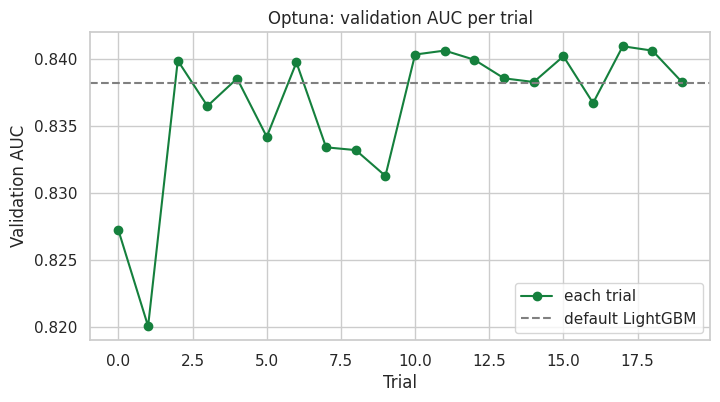

In [10]:
history = study.trials_dataframe()

plt.figure(figsize=(8, 4))
plt.plot(history["number"], history["value"], marker="o", color="#15803D", label="each trial")
plt.axhline(valid_auc["LightGBM (default)"], linestyle="--", color="gray", label="default LightGBM")
plt.title("Optuna: validation AUC per trial")
plt.xlabel("Trial")
plt.ylabel("Validation AUC")
plt.legend()
plt.savefig(os.path.join(FIG_DIR, "optuna_history.png"), dpi=130, bbox_inches="tight")
plt.show()

### Train the tuned model with the best settings

In [11]:
tuned = lgb.LGBMClassifier(**study.best_params, random_state=42, verbose=-1)
tuned.fit(X_train, y_train)

models["LightGBM (tuned)"] = tuned
valid_auc["LightGBM (tuned)"] = roc_auc_score(y_valid, tuned.predict_proba(X_valid)[:, 1])

best_on_valid = max(valid_auc, key=valid_auc.get)
print("Best model on the validation set:", best_on_valid)

Best model on the validation set: LightGBM (tuned)


## 4 · Test on data the models have never seen
Precision and recall use the usual 0.50 cut-off here. Notebook 04 replaces that cut-off with a cost-based one.
- **Precision:** of the customers we flag, how many really compress?
- **Recall:** of the customers who really compress, how many do we catch?

In [12]:
rows = []
for name, model in models.items():
    probs = model.predict_proba(X_test)[:, 1]
    flagged = (probs >= 0.5).astype(int)
    rows.append({
        "model": name,
        "validation AUC": valid_auc[name],
        "test AUC": roc_auc_score(y_test, probs),
        "precision @0.50": precision_score(y_test, flagged, zero_division=0),
        "recall @0.50": recall_score(y_test, flagged, zero_division=0),
    })

results = pd.DataFrame(rows).set_index("model").round(4)
results

,validation AUC,test AUC,precision @0.50,recall @0.50
model,,,,
Logistic regression,0.8296,0.8318,0.6562,0.2066
Decision tree,0.7660,0.7695,0.6105,0.1299
LightGBM (default),0.8382,0.8378,0.6333,0.2635
LightGBM (tuned),0.8409,0.8409,0.6381,0.2685


### Save the models for notebook 04

In [13]:
package = {"models": models, "features": features, "best_on_valid": best_on_valid}
joblib.dump(package, os.path.join(WORK_DIR, "trained_models.joblib"))
print("Saved trained_models.joblib")

Saved trained_models.joblib


## 5 · Do the engineered features really help? (ablation)
Feature importance says which features a model *uses*. It does not say which it *needs*. A fair test is to **remove a group of features and see what happens** to the validation AUC. The test set stays untouched.

The `_change` features are `_last3` minus `_first3`. Both of those stay in the table, so the model may not need the difference.

In [14]:
feature_sets = {
    "all features": features,
    "without the _change features": [c for c in features if not c.endswith("_change")],
    "only the _change features": [c for c in features if c.endswith("_change")],
}

rows = []
for name, columns in feature_sets.items():
    model = lgb.LGBMClassifier(random_state=42, verbose=-1)
    model.fit(X_train[columns], y_train)
    auc = roc_auc_score(y_valid, model.predict_proba(X_valid[columns])[:, 1])
    rows.append({"feature set": name, "number of features": len(columns), "validation AUC": auc})

pd.DataFrame(rows).round(4)

,feature set,number of features,validation AUC
0,all features,23,0.8382
1,without the _change features,19,0.8390
2,only the _change features,4,0.8151


## 6 · Summary
- The tuned LightGBM ranked best on validation and on test. Logistic regression is close behind and the shallow decision tree is clearly weaker.
- LightGBM's lead over logistic regression is small. On real data a simple model that almost matches a complex one is often the better choice, because it is easier to explain and maintain.
- Optuna improved only slightly on default LightGBM.
- At the default 0.50 cut-off every model catches only a small share of compressed customers (low recall). Notebook 04 fixes this by choosing the threshold from the cost of mistakes.
- The ablation: removing the `_change` features did not lower the validation AUC, because the same information is in the other columns. Importance shows what a model uses, not what it needs.

**Next:** `04_evaluation_and_export.ipynb`